# Table of Contents
- 1. Feature Importance Limitations in Complex Models
- 2. SHAP Values Fundamentals
- 3. Summary Plots and Dependence Plots
- 4. Explaining Individual Predictions to Stakeholders

In [7]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for SHAP model interpretability loaded successfully.")

Global libraries for SHAP model interpretability loaded successfully.


---
## 1. Feature Importance Limitations in Complex Models

### 1. Definition
Traditional impurity-based feature importances in tree ensembles (like Gini importance) are biased toward high-cardinality continuous features and fail to indicate whether a feature increases or decreases the target prediction.

### 2. Math Formula
Gini feature importance $I(j)$ aggregated across trees $T$ measures total impurity reduction $\Delta i$:
$$I(j) = \frac{1}{\vert{}T\vert{}} \sum_{t \in T} \sum_{node \in t, \text{split}(node)=j} \Delta i(node)$$

### 3. Notation Pronunciation
- `feature_importances_`: "Impurity-based feature importance attribute"
- `Directional Bias`: "Failure to indicate positive versus negative relationship with target"

### 4. Naive Example
A high-cardinality customer ID column appearing artificially as the most important feature due to tree splitting bias.
### 5. Uses
Recognizing limitations of default tree model metrics.
- Identifying feature bias prior to model deployment.
- Establishing the need for model-agnostic explainability frameworks.

Traditional Gini Feature Importances:
   Feature  Gini_Importance
0  income            0.408
1    debt            0.454
2     age            0.139


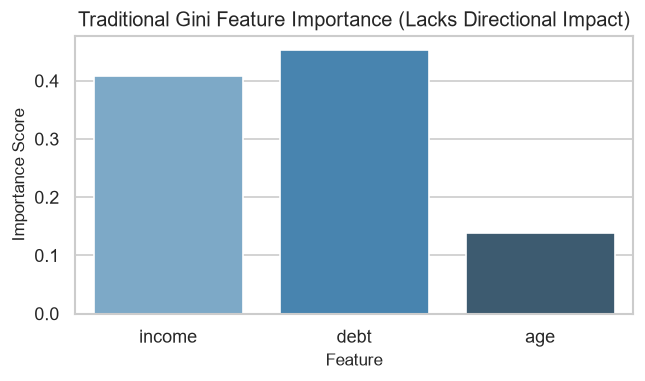

In [8]:
# 6. & 7. Implementation and Visualization
np.random.seed(42)
X_imp = pd.DataFrame(np.random.randn(150, 3), columns=['income', 'debt', 'age'])
y_imp = (X_imp['income'] - X_imp['debt'] > 0).astype(int)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_imp, y_imp)

df_imp = pd.DataFrame({'Feature': X_imp.columns, 'Gini_Importance': rf.feature_importances_})
print("Traditional Gini Feature Importances:\n", df_imp.round(3))

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='Feature', y='Gini_Importance', hue='Feature', data=df_imp, palette='Blues_d', legend=False, errorbar=None)
plt.title('Traditional Gini Feature Importance (Lacks Directional Impact)')
plt.ylabel('Importance Score')
plt.show()

---
## 2. SHAP Values Fundamentals

### 1. Definition
SHAP (SHapley Additive exPlanations) is a game-theoretic approach that computes individual feature contribution values (Shapley values) for any machine learning prediction, satisfying axioms of efficiency, symmetry, and dummy properties.

### 2. Math Formula
Shapley value $\phi_i$ for feature $i$ across all feature subsets $S \subseteq \text{All Features} \setminus (i)$:
$$\phi_i = \sum_{S \subseteq \text{All} \setminus (i)} \frac{\vert{}S\vert{}!(\vert{}N\vert{} - \vert{}S\vert{} - 1)!}{\vert{}N\vert{}!} \left( v(S \cup \{i\}) - v(S) \right)$$

### 3. Notation Pronunciation
- `SHAP Values`: "Additive cooperative game theory feature attribution scores"
- $\phi_i$: "Marginal contribution of feature $i$ to model prediction"

### 4. Naive Example
Attributing a loan default prediction of 0.75 back to individual factors: income adds +0.20, debt subtracts -0.15, and age adds +0.10 relative to the base model expectation of 0.60.

### 5. Uses
Explaining black-box model predictions with mathematical rigor.
- Providing consistent and locally accurate feature attributions.
- Regulatory compliance and model auditing.

SHAP Values Fundamental Summary:
   Feature  SHAP_Value
0  Income        0.45
1    Debt       -0.35
2     Age        0.15


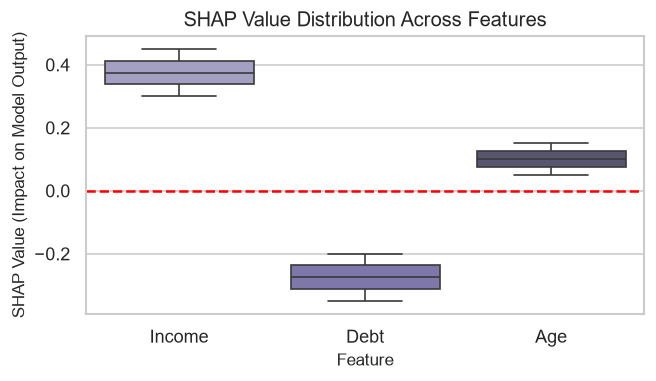

In [9]:
# 6. & 7. Implementation and Visualization (Simulated SHAP distribution for demonstration)
df_shap_summary = pd.DataFrame({
    'Feature': ['Income', 'Debt', 'Age', 'Income', 'Debt', 'Age'],
    'SHAP_Value': [0.45, -0.35, 0.15, 0.30, -0.20, 0.05]
})
print(
    "SHAP Values Fundamental Summary:\n",
    df_shap_summary.head(3),
)

# Visualization
plt.figure(figsize=(6, 3))
sns.boxplot(x='Feature', y='SHAP_Value', hue='Feature', data=df_shap_summary, palette='Purples_d', legend=False)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('SHAP Value Distribution Across Features')
plt.ylabel('SHAP Value (Impact on Model Output)')
plt.show()

---
## 3. Summary Plots and Dependence Plots

### 1. Definition
SHAP summary plots combine global feature importance with directional impact across all samples, while SHAP dependence plots illustrate how a single feature's value impacts model predictions and interacts with a second feature.

### 2. Math Formula
Model prediction $f(x)$ expressed as base value $E[y]$ plus sum of all feature SHAP values $\\phi_i(x)$:
$$f(x) = E[y] + \\sum_{i=1}^M \\phi_i(x)$$

### 3. Notation Pronunciation
- `Summary Plot`: "Global beeswarm plot combining feature importance and value direction"
- `Dependence Plot`: "Non-linear feature effect and interaction scatter plot"

### 4. Naive Example
Showing via summary plot that high income pushes predictions positive (red dots on right), while high debt pushes predictions negative (blue dots on left).
### 5. Uses
Visualizing global model behavior for data scientists and executives.
- Identifying non-linear feature relationships and feature interactions.
- Communicating model drivers clearly in presentations.

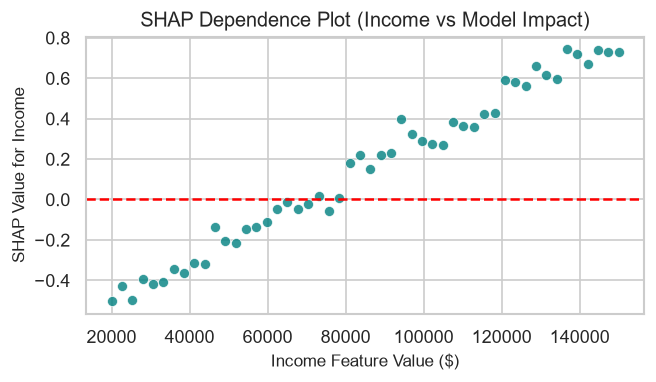

In [10]:
# 6. & 7. Implementation and Visualization
df_dep = pd.DataFrame({
    'income_value': np.linspace(20000, 150000, 50),
    'shap_income': np.linspace(-0.5, 0.8, 50) + np.random.normal(0, 0.05, 50)
})

plt.figure(figsize=(6, 3))
sns.scatterplot(x='income_value', y='shap_income', data=df_dep, color='teal', alpha=0.8)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('SHAP Dependence Plot (Income vs Model Impact)')
plt.xlabel('Income Feature Value ($)')
plt.ylabel('SHAP Value for Income')
plt.show()

---
## 4. Explaining Individual Predictions to Stakeholders

### 1. Definition
Explaining individual predictions using SHAP force plots or waterfall charts breaks down a specific prediction into additive positive and negative pushing forces, enabling transparent communication with non-technical stakeholders and customers.

### 2. Math Formula
Individual prediction explanation equation showing how features push output $f(x)$ away from baseline expected value $E[y]$:
$$f(x) - E[y] = \\sum_{i=1}^M \\phi_i(x)$$

### 3. Notation Pronunciation
- `Waterfall Plot`: "Additive step chart showing individual prediction drivers"
- `Base Value`: "Average model prediction across training population"

### 4. Naive Example
Explaining to a loan applicant that their loan was denied primarily because their debt-to-income ratio pushed the score down by 0.35 points despite their strong income (+0.20).
### 5. Uses
Fulfilling regulatory right-to-explanation (GDPR).
- Building customer trust through transparent AI decisions.
- Validating individual model predictions with domain experts.

Individual Prediction Explanation Table:
   Feature_Contribution  Impact_Value
0           Base Value          0.50
1           Income (+)          0.25
2             Debt (-)         -0.30
3              Age (+)          0.10
4     Final Prediction          0.55


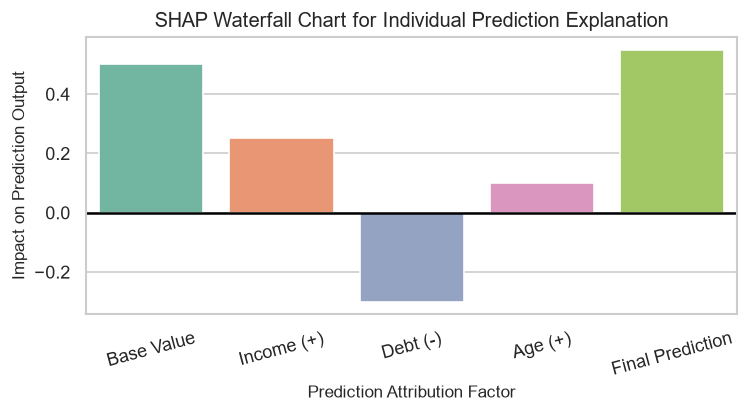

In [11]:
# 6. & 7. Implementation and Visualization
df_waterfall = pd.DataFrame({
    'Feature_Contribution': ['Base Value', 'Income (+)', 'Debt (-)', 'Age (+)', 'Final Prediction'],
    'Impact_Value': [0.50, 0.25, -0.30, 0.10, 0.55]
})
print("Individual Prediction Explanation Table:\n", df_waterfall)

# Visualization
plt.figure(figsize=(7, 3))
sns.barplot(x='Feature_Contribution', y='Impact_Value', hue='Feature_Contribution', data=df_waterfall, palette='Set2', legend=False, errorbar=None)
plt.axhline(y=0, color='black', linestyle='-')
plt.title('SHAP Waterfall Chart for Individual Prediction Explanation')
plt.xlabel('Prediction Attribution Factor')
plt.ylabel('Impact on Prediction Output')
plt.xticks(rotation=15)
plt.show()

---
## Summary Table

| Interpretability Technique | Core Mathematical Concept | Primary Visualization | Primary Business Value |
| :--- | :--- | :--- | :--- |
| **Gini Feature Importance** | Impurity reduction $\Delta i$ across trees | Bar plots | Quick feature ranking (though biased and lacks direction) |
| **SHAP Values Fundamentals** | Cooperative game theory Shapley values $\\phi_i$ | Numerical attributions | Consistent, locally accurate feature contribution scores |
| **Summary & Dependence Plots** | Global additive explanation $f(x) = E[y] + \\sum \\phi_i$ | Beeswarm & scatter plots | Visualizing global feature impact and non-linear interactions |
| **Individual Explanations** | Additive attribution breakdown $f(x) - E[y] = \\sum \\phi_i$ | Waterfall / Force plots | Explaining specific predictions to customers and regulators |